# Base e Importações

## Importações

In [11]:
!pip install xgboost
!pip install shap
import pandas as pd
from pathlib import Path
import numpy as np
import shap
import json
from IPython.display import display
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from xgboost import XGBRegressor
from sklearn.model_selection import TimeSeriesSplit
from sklearn.model_selection import RandomizedSearchCV

## Base

In [3]:
base_path = Path('data/processed/base_final.parquet')
if not base_path.exists():
    base_path = Path('base_final.parquet')

base = pd.read_parquet(base_path)

In [4]:
base.head()

,subsystem_code,timestamp,load_mw,source_year,precipitation_mm,pressure_station_hpa,pressure_max_hpa,pressure_min_hpa,global_radiation_kj_m2,temperature_c,...,load_mean_3h,load_std_3h,load_mean_6h,load_std_6h,load_mean_24h,load_std_24h,ramp_1h,target_load_1h,target_load_6h,target_load_24h
0,NE,2022-01-08 00:00:00,11926.333,2022,0.520000,974.148148,974.203704,973.448148,47.800000,24.492593,...,12420.102000,134.929127,12237.736833,221.810606,11584.597667,583.661108,-244.169,11635.094,9793.342,11660.956
1,NE,2022-01-08 01:00:00,11635.094,2022,0.253333,973.319643,973.403571,972.975000,1.060000,24.185714,...,12233.397333,292.610669,12222.878833,241.764288,11583.075958,582.678831,-338.512,11402.214,9865.790,11290.670
2,NE,2022-01-08 02:00:00,11402.214,2022,0.238298,974.063793,974.348276,973.979310,16.883333,24.013793,...,11942.090667,315.171078,12139.194667,343.039821,11584.575750,582.768185,-291.239,11147.334,10122.028,11049.698
3,NE,2022-01-08 03:00:00,11147.334,2022,0.486957,973.198214,973.580357,973.164286,615.487500,23.726786,...,11654.547000,262.600449,12037.324500,459.007934,11585.088542,582.594832,-232.880,10927.972,10205.706,10924.900
4,NE,2022-01-08 04:00:00,10927.972,2022,0.195652,973.167273,973.587273,973.147273,426.871429,23.521818,...,11394.880667,243.962677,11814.139000,518.641087,11581.656042,585.017287,-254.880,10275.910,10321.871,10726.672


In [5]:
n = len(base)
print(f"Number of rows: {n}")

Number of rows: 40704


In [6]:
train_end = int(n * 0.7)
val_end = int(n * 0.85)

train = base.iloc[:train_end]
val   = base.iloc[train_end:val_end]
test  = base.iloc[val_end:]

print(len(train), len(val), len(test))

28492 6106 6106


In [7]:
print("Inicio e fim do conjunto de treino:", train['timestamp'].min(), train['timestamp'].max())
print("Inicio e fim do conjunto de validação:", val['timestamp'].min(), val['timestamp'].max())
print("Inicio e fim do conjunto de teste:", test['timestamp'].min(), test['timestamp'].max())

Inicio e fim do conjunto de treino: 2022-01-08 00:00:00 2025-04-09 03:00:00
Inicio e fim do conjunto de validação: 2025-04-09 04:00:00 2025-12-19 13:00:00
Inicio e fim do conjunto de teste: 2025-12-19 14:00:00 2026-08-30 23:00:00


In [8]:
features_1 = [
    'hour_sin',
    'hour_cos',
    'weekday_sin',
    'weekday_cos',
    'month_sin',
    'month_cos',
    'weekend',
    'is_holiday_national'
]

features_2 = [
    'hour_sin',
    'hour_cos',
    'weekday_sin',
    'weekday_cos',
    'month_sin',
    'month_cos',
    'weekend',
    'is_holiday_national',
    'load_mw'
]

features_3 = [
    'hour_sin',
    'hour_cos',
    'weekday_sin',
    'weekday_cos',
    'month_sin',
    'month_cos',
    'weekend',
    'is_holiday_national',
    'load_mw', 'load_lag_1h', 'load_lag_2h', 'load_lag_3h', 'load_lag_24h', 'load_lag_48h', 'load_lag_168h'
]

features_4 = [
    'hour_sin',
    'hour_cos',
    'weekday_sin',
    'weekday_cos',
    'month_sin',
    'month_cos',
    'weekend',
    'is_holiday_national',
    'load_mw', 'load_lag_1h', 'load_lag_2h', 'load_lag_3h', 'load_lag_24h', 'load_lag_48h', 'load_lag_168h',
    'load_mean_3h',
    'load_mean_6h',
    'load_mean_24h',

    'load_std_3h',
    'load_std_6h',
    'load_std_24h',

    'ramp_1h'
]

features_5 = [
    'hour_sin',
        'hour_cos',
        'weekday_sin',
        'weekday_cos',
        'month_sin',
        'month_cos',
        'weekend',
        'is_holiday_national',
        'load_mw', 'load_lag_1h', 'load_lag_2h', 'load_lag_3h', 'load_lag_24h', 'load_lag_48h', 'load_lag_168h',
        'load_mean_3h',
        'load_mean_6h',
        'load_mean_24h',

        'load_std_3h',
        'load_std_6h',
        'load_std_24h',

        'ramp_1h',
        'precipitation_mm', 'pressure_station_hpa', 'global_radiation_kj_m2', 'temperature_c', 'humidity_pct', 'wind_gust_ms', 'wind_speed_ms'
]

target_1 = 'target_load_1h'
target_6 = 'target_load_6h'
target_24 = 'target_load_24h'

In [9]:
train_val = pd.concat([train, val])

## Modelo

In [10]:
features_1h = features_4
target_1h = 'target_load_1h'

features_6h = features_5
target_6h = 'target_load_6h'

features_24h = features_3
target_24h = 'target_load_24h'

model_1h = XGBRegressor()
model_1h.load_model('xgb_1h.json')

model_6h = XGBRegressor()
model_6h.load_model('xgb_6h.json')

model_24h = XGBRegressor()
model_24h.load_model('xgb_24h.json')

pred_test_1h = model_1h.predict(test[features_1h])
pred_test_6h = model_6h.predict(test[features_6h])
pred_test_24h = model_24h.predict(test[features_24h])

# SHAP

## 1h

In [12]:
X_test_1h = test[features_1h]

explainer_1h = shap.TreeExplainer(model_1h)

shap_values_1h = explainer_1h.shap_values(X_test_1h)

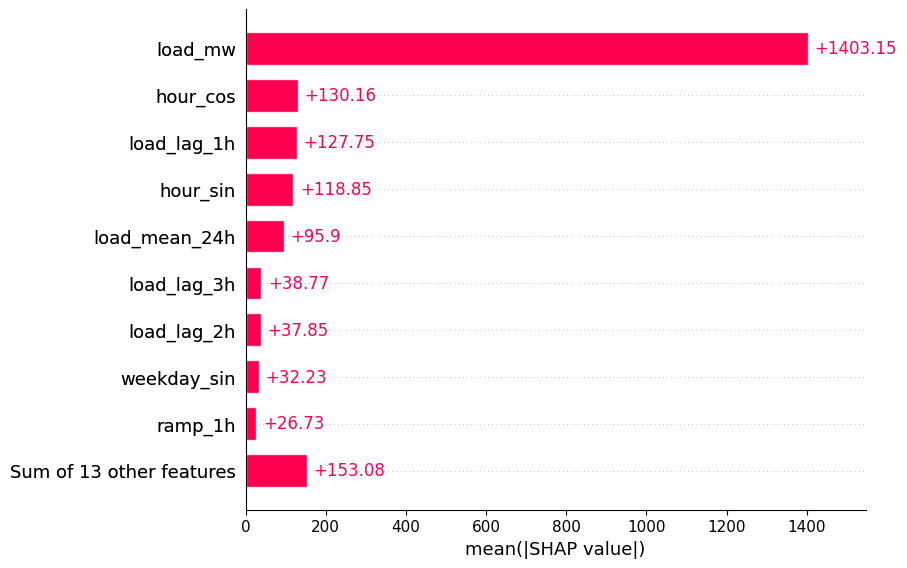

In [14]:
shap_explanation_1h = explainer_1h(X_test_1h)

shap.plots.bar(
    shap_explanation_1h,
    max_display=10
)

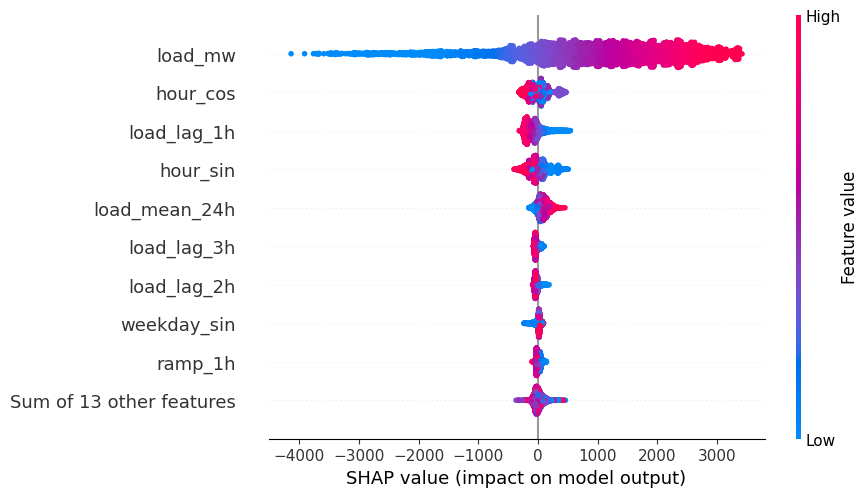

In [16]:
shap.plots.beeswarm(
    shap_explanation_1h
)

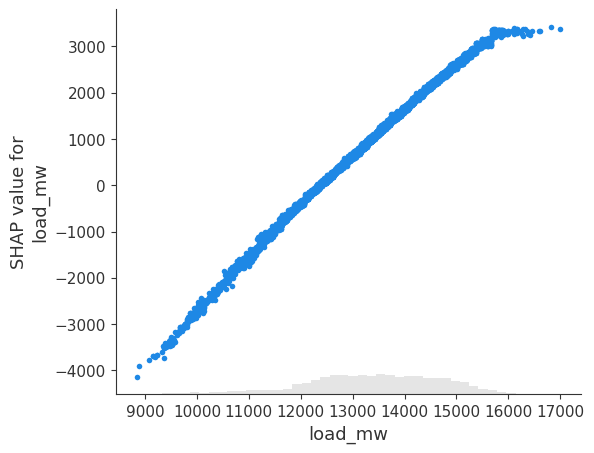

In [18]:
shap.plots.scatter(
    shap_explanation_1h[:, "load_mw"]
)

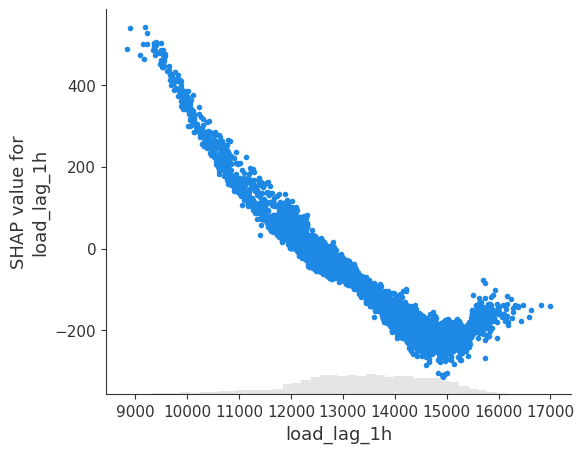

In [20]:
shap.plots.scatter(
    shap_explanation_1h[:, "load_lag_1h"]
)

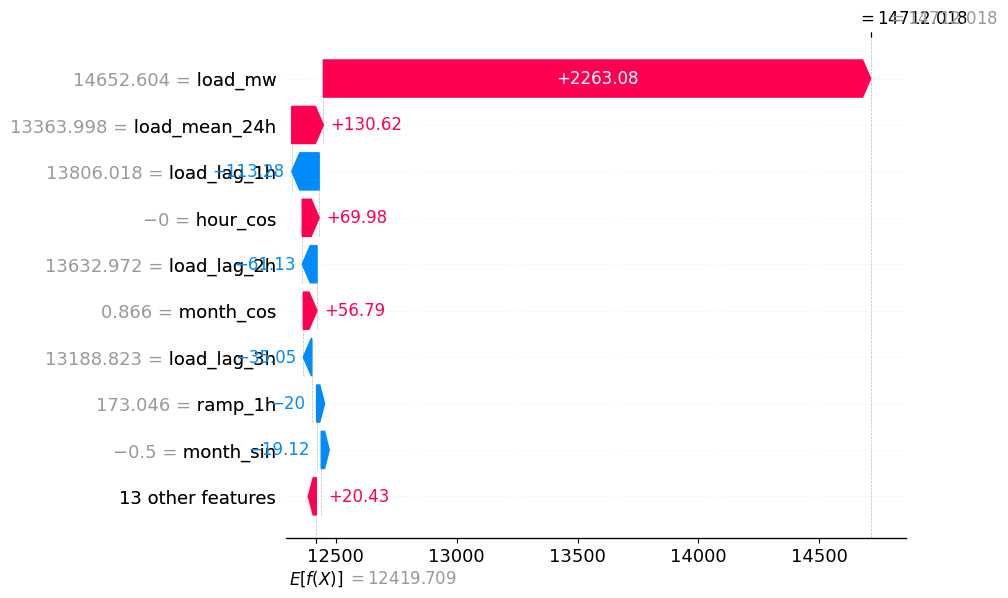

In [22]:
i = 100

shap.plots.waterfall(
    shap_explanation_1h[i]
)

Índice: 35608
Observado: 14603.15 MW
Previsto: 13307.67 MW
Erro absoluto: 1295.48 MW


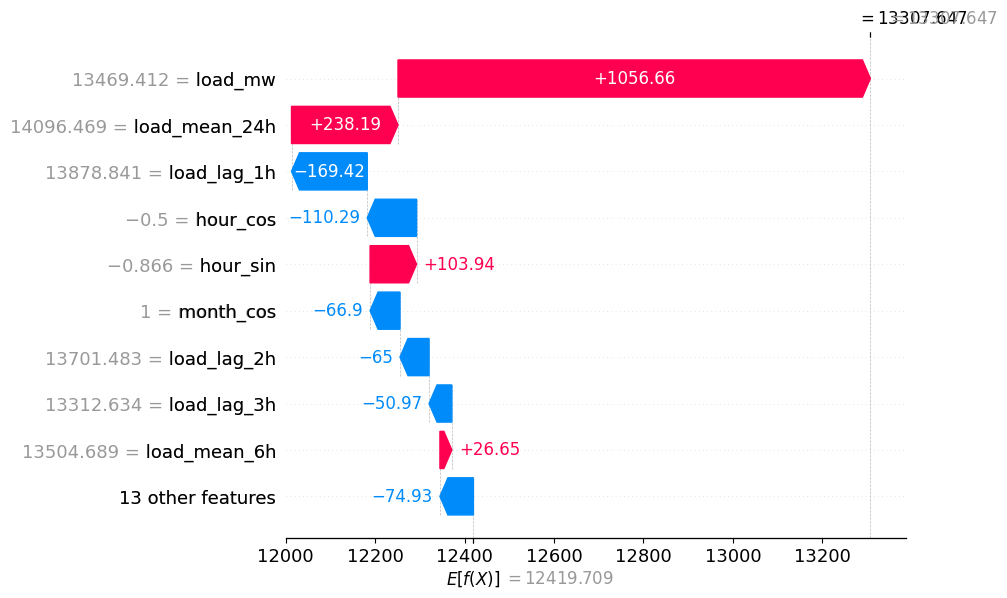

In [24]:
# Valores observados na mesma ordem das previsões
y_test_1h = test.loc[X_test_1h.index, target_1h].to_numpy()

# Posição do maior erro absoluto
abs_error_1h = np.abs(y_test_1h - pred_test_1h)
worst_position = int(np.argmax(abs_error_1h))
worst_index = X_test_1h.index[worst_position]

print(f"Índice: {worst_index}")
print(f"Observado: {y_test_1h[worst_position]:.2f} MW")
print(f"Previsto: {pred_test_1h[worst_position]:.2f} MW")
print(f"Erro absoluto: {abs_error_1h[worst_position]:.2f} MW")

shap.plots.waterfall(
    shap_explanation_1h[worst_position]
)

## 6h

In [25]:
X_test_6h = test[features_6h]

explainer_6h = shap.TreeExplainer(model_6h)

shap_values_6h = explainer_6h.shap_values(X_test_6h)

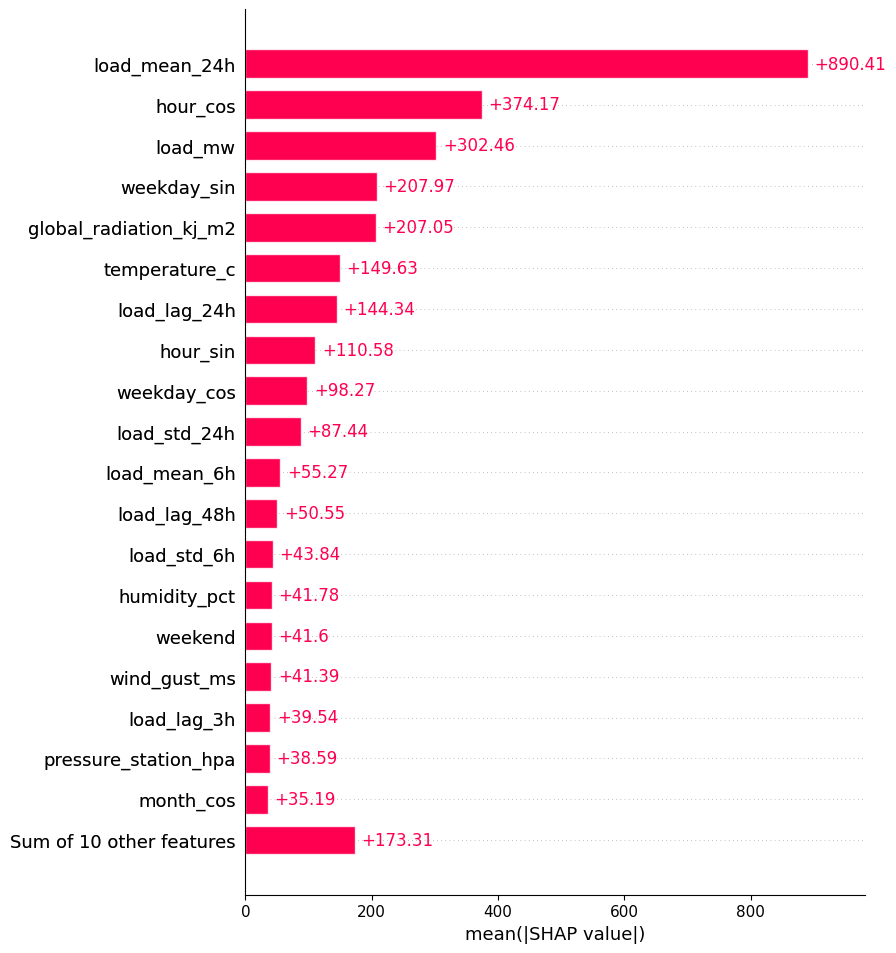

In [27]:
shap_explanation_6h = explainer_6h(X_test_6h)

shap.plots.bar(
    shap_explanation_6h,
    max_display=20
)

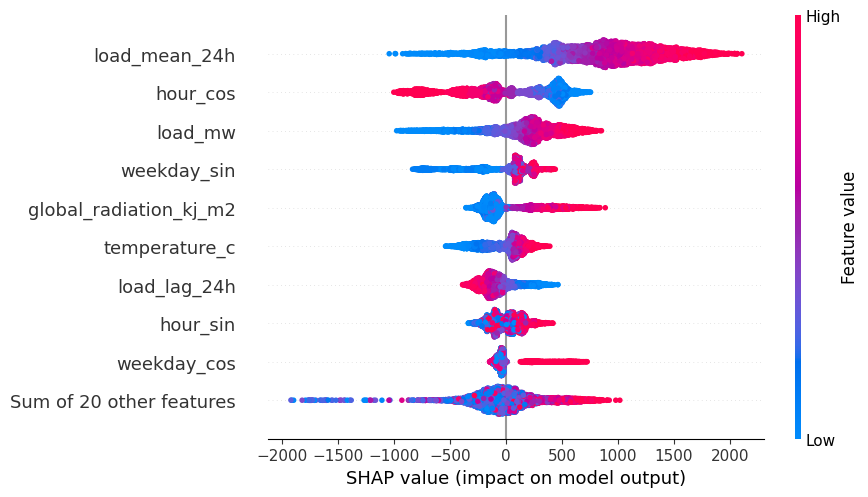

In [28]:
shap.plots.beeswarm(
    shap_explanation_6h
)

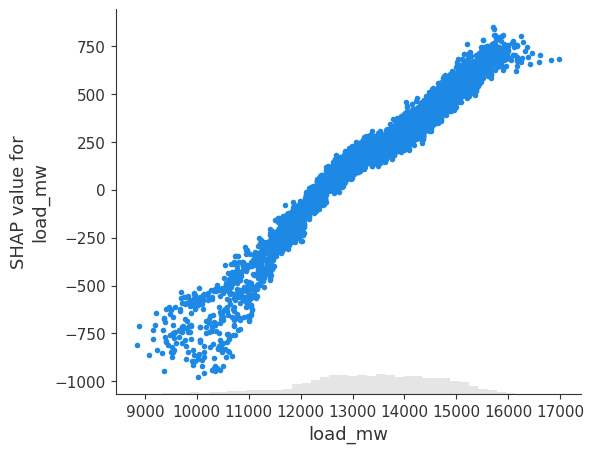

In [29]:
shap.plots.scatter(
    shap_explanation_6h[:, "load_mw"]
)

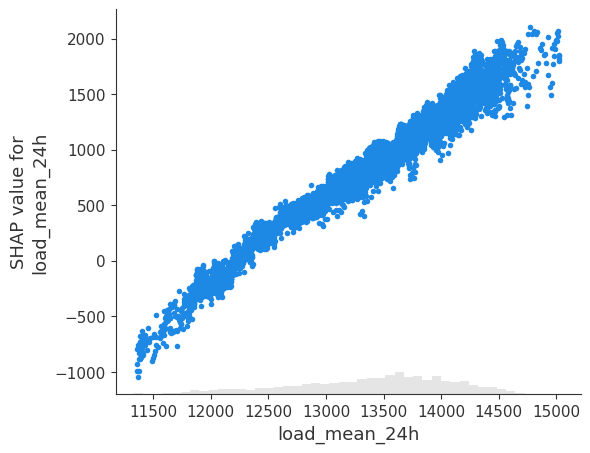

In [31]:
shap.plots.scatter(
    shap_explanation_6h[:, "load_mean_24h"]
)

Índice: 34881
Observado: 12303.17 MW
Previsto: 14989.84 MW
Erro absoluto: 2686.67 MW


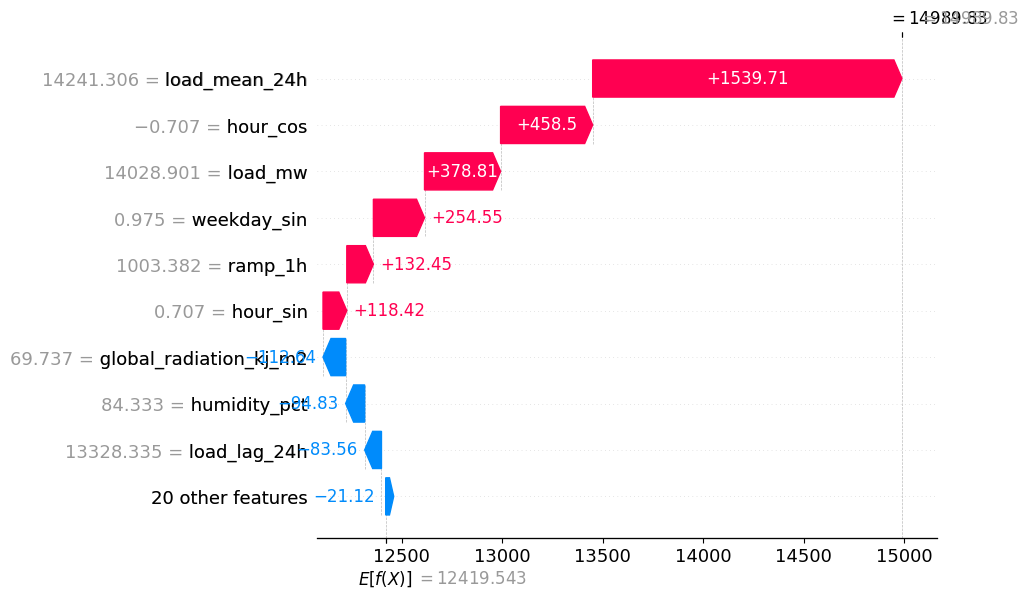

In [32]:
# Valores observados na mesma ordem das previsões
y_test_6h = test.loc[X_test_6h.index, target_6h].to_numpy()

# Posição do maior erro absoluto
abs_error_6h = np.abs(y_test_6h - pred_test_6h)
worst_position = int(np.argmax(abs_error_6h))
worst_index = X_test_6h.index[worst_position]

print(f"Índice: {worst_index}")
print(f"Observado: {y_test_6h[worst_position]:.2f} MW")
print(f"Previsto: {pred_test_6h[worst_position]:.2f} MW")
print(f"Erro absoluto: {abs_error_6h[worst_position]:.2f} MW")

shap.plots.waterfall(
    shap_explanation_6h[worst_position]
)

## 24h

In [33]:
X_test_24h = test[features_24h]

explainer_24h = shap.TreeExplainer(model_24h)

shap_values_24h = explainer_24h.shap_values(X_test_24h)

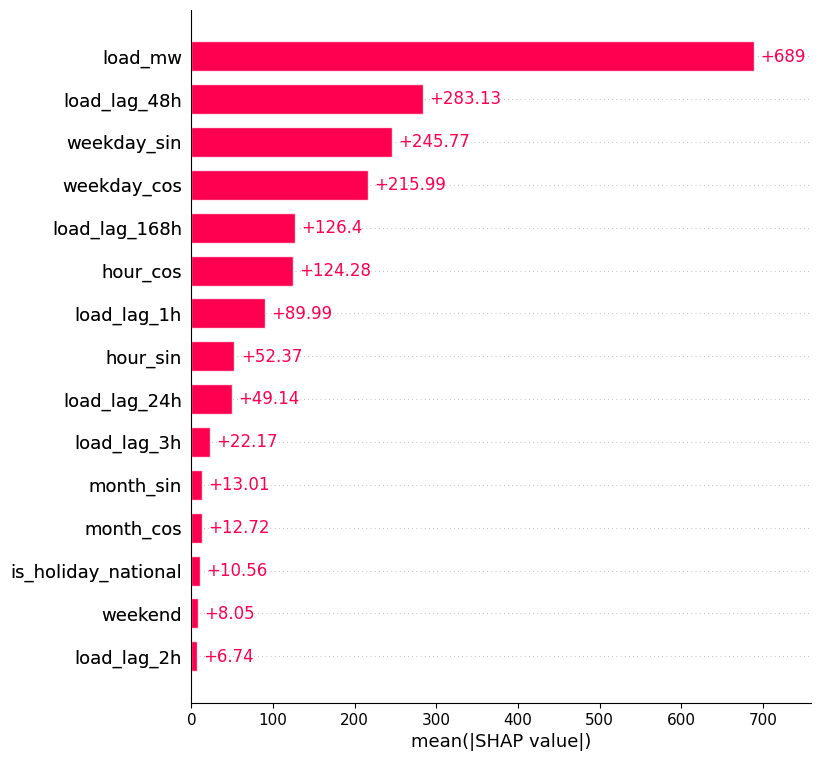

In [34]:
shap_explanation_24h = explainer_24h(X_test_24h)

shap.plots.bar(
    shap_explanation_24h,
    max_display=20
)

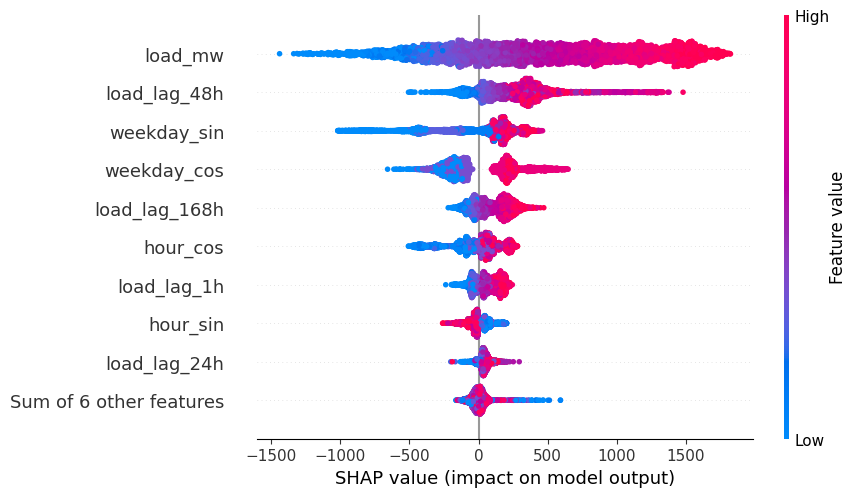

In [35]:
shap.plots.beeswarm(
    shap_explanation_24h
)

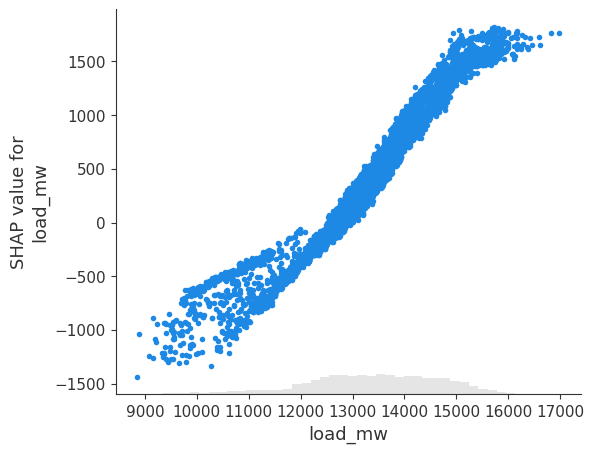

In [36]:
shap.plots.scatter(
    shap_explanation_24h[:, "load_mw"]
)

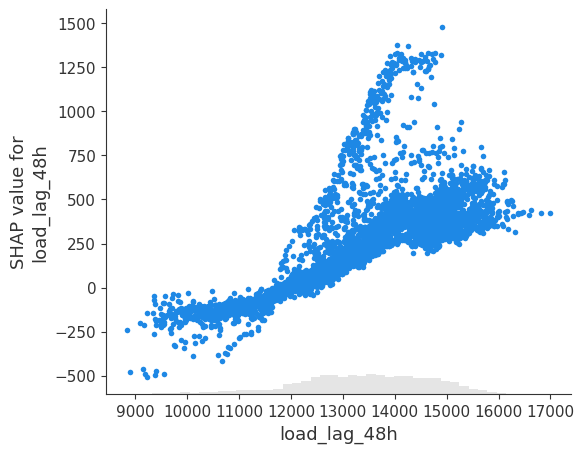

In [38]:
shap.plots.scatter(
    shap_explanation_24h[:, "load_lag_48h"]
)

Índice: 37093
Observado: 8889.52 MW
Previsto: 12593.20 MW
Erro absoluto: 3703.68 MW


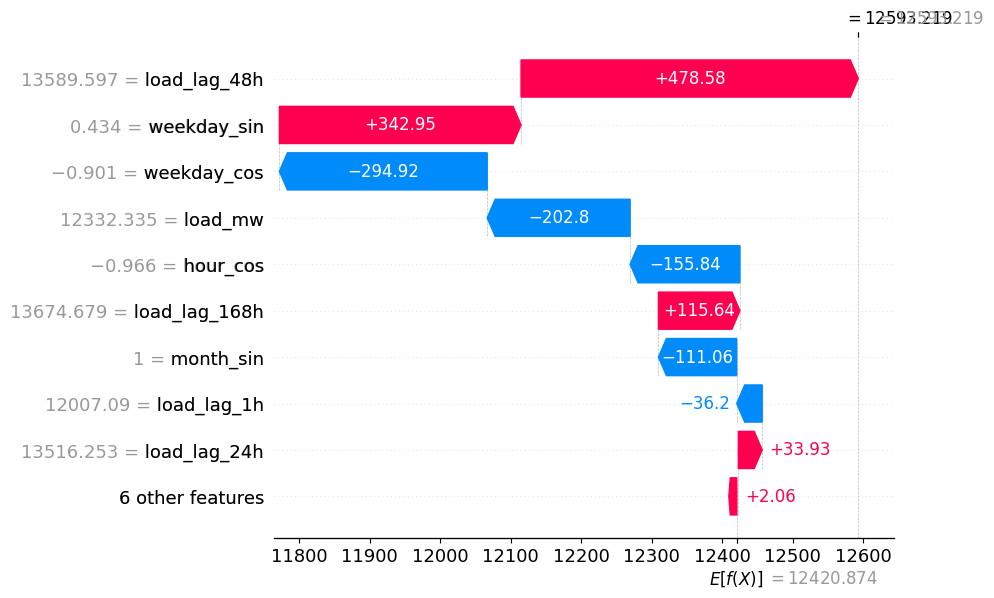

In [39]:
# Valores observados na mesma ordem das previsões
y_test_24h = test.loc[X_test_24h.index, target_24h].to_numpy()

# Posição do maior erro absoluto
abs_error_24h = np.abs(y_test_24h - pred_test_24h)
worst_position = int(np.argmax(abs_error_24h))
worst_index = X_test_24h.index[worst_position]

print(f"Índice: {worst_index}")
print(f"Observado: {y_test_24h[worst_position]:.2f} MW")
print(f"Previsto: {pred_test_24h[worst_position]:.2f} MW")
print(f"Erro absoluto: {abs_error_24h[worst_position]:.2f} MW")

shap.plots.waterfall(
    shap_explanation_24h[worst_position]
)

# Relatório final

A célula seguinte consolida, de forma reproduzível, as métricas de desempenho, os piores casos e as cinco variáveis de maior importância SHAP em cada horizonte.

In [40]:
# Consolidação quantitativa dos resultados apresentados no notebook
config_relatorio = {
    '1h': {
        'features': features_1h, 'target': target_1h,
        'pred': pred_test_1h, 'explanation': shap_explanation_1h
    },
    '6h': {
        'features': features_6h, 'target': target_6h,
        'pred': pred_test_6h, 'explanation': shap_explanation_6h
    },
    '24h': {
        'features': features_24h, 'target': target_24h,
        'pred': pred_test_24h, 'explanation': shap_explanation_24h
    }
}

metricas_finais = []
ranking_shap_final = []

for horizonte, cfg in config_relatorio.items():
    y_true = test[cfg['target']].to_numpy()
    y_pred = np.asarray(cfg['pred'])
    erros = y_true - y_pred
    erros_abs = np.abs(erros)
    pior_posicao = int(np.argmax(erros_abs))
    ss_res = np.sum(erros ** 2)
    ss_tot = np.sum((y_true - y_true.mean()) ** 2)

    metricas_finais.append({
        'horizonte': horizonte,
        'n_features': len(cfg['features']),
        'MAE (MW)': erros_abs.mean(),
        'RMSE (MW)': np.sqrt(np.mean(erros ** 2)),
        'MAPE (%)': np.mean(erros_abs / np.abs(y_true)) * 100,
        'R2': 1 - ss_res / ss_tot,
        'vies_obs_menos_prev (MW)': erros.mean(),
        'maior_erro_abs (MW)': erros_abs[pior_posicao],
        'data_pior_caso': pd.to_datetime(test.iloc[pior_posicao]['timestamp'])
    })

    importancia = pd.Series(
        np.abs(cfg['explanation'].values).mean(axis=0),
        index=cfg['features'],
        name='mean_abs_shap_mw'
    ).sort_values(ascending=False)

    top_5 = importancia.head(5).rename_axis('variavel').reset_index()
    top_5.insert(0, 'horizonte', horizonte)
    ranking_shap_final.append(top_5)

resumo_metricas_final = pd.DataFrame(metricas_finais).set_index('horizonte')
top_features_shap_final = pd.concat(ranking_shap_final, ignore_index=True)

display(
    resumo_metricas_final.style.format({
        'MAE (MW)': '{:.2f}',
        'RMSE (MW)': '{:.2f}',
        'MAPE (%)': '{:.2f}',
        'R2': '{:.3f}',
        'vies_obs_menos_prev (MW)': '{:+.2f}',
        'maior_erro_abs (MW)': '{:.2f}'
    })
)

display(
    top_features_shap_final.style.format({'mean_abs_shap_mw': '{:.2f}'})
)

,n_features,MAE (MW),RMSE (MW),MAPE (%),R2,vies_obs_menos_prev (MW),maior_erro_abs (MW),data_pior_caso
horizonte,,,,,,,,
1h,22,149.63,203.60,1.14,0.976,+2.69,1295.48,2026-01-30 16:00:00
6h,29,399.32,516.20,3.06,0.849,+1.48,2686.67,2025-12-31 09:00:00
24h,15,370.85,526.98,2.86,0.843,+35.46,3703.68,2026-04-02 13:00:00


,horizonte,variavel,mean_abs_shap_mw
0,1h,load_mw,1403.15
1,1h,hour_cos,130.16
2,1h,load_lag_1h,127.75
3,1h,hour_sin,118.85
4,1h,load_mean_24h,95.90
5,6h,load_mean_24h,890.41
6,6h,hour_cos,374.17
7,6h,load_mw,302.46
8,6h,weekday_sin,207.97
9,6h,global_radiation_kj_m2,207.05


## Síntese dos resultados



A análise utilizou **40.704 observações horárias do subsistema Nordeste**, entre 08/01/2022 e 30/08/2026. A separação foi temporal: 70% para treino, 15% para validação e 15% para teste. O teste contém 6.106 observações, de 19/12/2025 a 30/08/2026.

| Horizonte | Variáveis | MAE (MW) | RMSE (MW) | MAPE | R² | Viés observado − previsto (MW) | Maior erro absoluto (MW) |
|---|---:|---:|---:|---:|---:|---:|---:|
| 1h | 22 | 149,63 | 203,60 | 1,14% | 0,976 | +2,69 | 1.295,48 |
| 6h | 29 | 399,32 | 516,20 | 3,06% | 0,849 | +1,48 | 2.686,67 |
| 24h | 15 | 370,85 | 526,98 | 2,86% | 0,843 | +35,46 | 3.703,68 |

O modelo de **1h** apresentou o melhor desempenho e viés praticamente nulo. A explicação é fortemente concentrada na carga atual (`load_mw`), responsável por aproximadamente **64,8%** da soma das importâncias SHAP médias. Seu efeito é quase monotônico: cargas atuais mais altas elevam diretamente a previsão de 1h.

No horizonte de **6h**, a importância se distribui por mais fatores. A média móvel de 24h (`load_mean_24h`) lidera com cerca de **28,4%**, seguida pelo ciclo horário, carga atual e ciclo semanal. Radiação global e temperatura aparecem entre as variáveis principais, indicando que as condições meteorológicas passam a contribuir de forma relevante nesse horizonte.

No modelo de **24h**, a carga atual ainda lidera (**35,3%**), mas as defasagens de 48h e 168h e os termos do dia da semana ganham peso. Isso mostra maior dependência dos padrões diários e semanais. Apesar de o MAE ser ligeiramente menor que no modelo de 6h, o RMSE e o pior erro são maiores, sinalizando risco de erros extremos mais severos.

### Piores casos

- **1h — 30/01/2026 16:00:** observado 14.603,15 MW e previsto 13.307,67 MW; subestimação de 1.295,48 MW.
- **6h — 31/12/2025 09:00:** observado 12.303,17 MW e previsto 14.989,84 MW; superestimação de 2.686,67 MW.
- **24h — 02/04/2026 13:00:** observado 8.889,52 MW e previsto 12.593,20 MW; superestimação de 3.703,68 MW.

### Conclusão

Os resultados indicam um modelo muito robusto para previsão imediata e uma perda esperada de precisão conforme o horizonte aumenta. Para 6h e 24h, calendário, meteorologia e padrões históricos tornam-se mais importantes, mas eventos atípicos ainda podem produzir erros operacionais elevados. Recomenda-se monitorar separadamente feriados, vésperas de feriado, rampas e extremos de carga, além das métricas médias.
